# 30 · Buyers of brand-new tokens (work package 19)

**Work package 19** of the [applications plan](../../research/implementation_plan_applications.md), section 19.
WP15 (notebook 26) ranks accounts for a token the model knows. A token launched after the evaluation point has no
column in the model, and tokens that did not exist at $t$ are 29% of what traders pick up on the test. Here the
token's **first buyers** stand in for its column:

- **New tokens:** first traded in $[t, t + 24\text{ h})$, with at least 3 *seed* accounts (audience accounts that
  trade it in its first hour) and at least 10 buyers.
- **Audience:** accounts with at least one token in the 14 days before $t$, minus the seeds (about 140,000).
- **Buyers:** audience accounts whose first trade of the token falls in the 24 hours after its first hour.
- Everything a score uses is known **one hour after launch**: account histories before $t$ and the seeds.

| Score | Account $u$ scores high if ... |
| --- | --- |
| seed profile | its 14-day tokens are the tokens the seeds hold: $W p$, $p_j$ = seeds holding $j$ |
| seed profile, idf | the same, with common tokens down-weighted |
| recommender | its tokens are *similar* (frozen blend's co-trading similarity) to the seeds' tokens: $W (S p)$ |
| activity (baseline) | it trades many tokens (as WP15) |
| launch hunters (baseline) | it often buys tokens within a day of their launch |

One score and one baseline are chosen on Dev A. **Criterion (stated in the plan before the run):** on the 14 test
points, the chosen score beats the chosen baseline in mean recall@1000 per point, with a 95% bootstrap interval
over points that excludes zero. Results from `src/scripts/build_new_token_audience.py`.

In [1]:
import sys

sys.path.append("../scripts")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import plots
import protocol as pc
import stats

plots.style()
pd.set_option("display.float_format", "{:,.3f}".format)
WP19 = pc.RESULTS_DIR / "wp19"
PARTS = ["dev_a", "dev_b", "test"]
SCORES = ["seed profile", "seed profile, idf", "recommender"]
BASELINES = ["activity", "launch hunters"]
tokens = {part: pd.read_parquet(WP19 / f"tokens_{part}.parquet") for part in PARTS}
without_farms = {part: pd.read_parquet(WP19 / f"tokens_{part}_without_farms.parquet") for part in ("dev_b", "test")}


def per_point(table: pd.DataFrame, metric: str = "recall_1000") -> pd.DataFrame:
    """Mean of a metric over the new tokens of each point, per method: one row per (method, point)."""
    return table.groupby(["method", "point"])[metric].mean().reset_index()


one = {part: t[t["method"] == "activity"] for part, t in tokens.items()}
pd.DataFrame({part: {"points with a new token": t["point"].nunique(), "new tokens": len(t),
                     "tokens per point (mean)": t.groupby("point").size().mean(), "seeds (median)": t["seeds"].median(),
                     "buyers (median)": t["buyers"].median(), "audience (mean)": t["audience"].mean()} for part, t in one.items()})  # fmt: skip

,dev_a,dev_b,test
points with a new token,9.000,11.000,14.000
new tokens,44.000,51.000,71.000
tokens per point (mean),4.889,4.636,5.071
seeds (median),42.500,31.000,27.000
buyers (median),22.000,35.000,19.000
audience (mean),"166,262.318","121,016.196","142,642.127"


Only launches that take off qualify: most new tokens get fewer than 10 buyers after their first hour (most pick-ups
of new tokens happen *in* the first hour, notebook 13). Points without a qualifying token have no value and are
left out of the paired comparison.

## 1. Choosing on Dev A

In [2]:
dev_a = per_point(tokens["dev_a"]).groupby("method")["recall_1000"].mean()
dev_a.sort_values(ascending=False).to_frame("Dev A recall@1000")

,Dev A recall@1000
method,
"seed profile, idf",0.552
seed profile,0.537
recommender,0.420
launch hunters,0.300
activity,0.216
random,0.008


In [3]:
SCORE = dev_a[SCORES].idxmax()
BASELINE = dev_a[BASELINES].idxmax()
print(f"Chosen on Dev A: score '{SCORE}', baseline '{BASELINE}'")

Chosen on Dev A: score 'seed profile, idf', baseline 'launch hunters'


## 2. Dev B and the test

In [4]:
def compare(table: pd.DataFrame, metric: str = "recall_1000") -> pd.DataFrame:
    frames = per_point(table, metric)
    results = {m: frames[frames["method"] == m][["point", metric]].reset_index(drop=True) for m in [BASELINE, SCORE, *[x for x in SCORES + BASELINES + ["random"] if x not in (SCORE, BASELINE)]]}
    return stats.compare(results, baseline=BASELINE, metric=metric)


report = pd.concat({part: compare(tokens[part]) for part in ("dev_b", "test")}, names=["part"]).droplevel(1)
report[["model", "points", "mean", "mean_difference", "interval_low", "interval_high", "wins"]]

,model,points,mean,mean_difference,interval_low,interval_high,wins
part,,,,,,,
dev_b,launch hunters,11,0.419,NaN,NaN,NaN,NaN
dev_b,"seed profile, idf",11,0.656,0.237,0.123,0.362,10 of 11
dev_b,seed profile,11,0.655,0.235,0.120,0.363,10 of 11
dev_b,recommender,11,0.567,0.148,0.048,0.257,8 of 11
dev_b,activity,11,0.330,-0.089,-0.207,-0.002,4 of 11
dev_b,random,11,0.014,-0.406,-0.489,-0.327,0 of 11
test,launch hunters,14,0.484,NaN,NaN,NaN,NaN
test,"seed profile, idf",14,0.715,0.230,0.121,0.365,11 of 14
test,seed profile,14,0.704,0.220,0.111,0.357,11 of 14


In [5]:
row = report.loc["test"].set_index("model").loc[SCORE]
met = row["mean_difference"] > 0 and row["interval_low"] > 0
print(f"Test: {SCORE} {row['mean']:.3f} against {BASELINE} {row['mean'] - row['mean_difference']:.3f}, difference "
      f"{row['mean_difference']:+.3f} [{row['interval_low']:+.3f}, {row['interval_high']:+.3f}], {row['wins']} -> criterion {'MET' if met else 'NOT met'}")  # fmt: skip

Test: seed profile, idf 0.715 against launch hunters 0.484, difference +0.230 [+0.121, +0.365], 11 of 14 -> criterion MET


## 3. Checks: precision, farms, late buyers

- **precision@100:** of the first 100 accounts, the share that buy.
- **Without farms:** WP10's farm groups removed from the audience and the buyers (as WP15).
- **Late buyers only:** recall counting only buyers who arrive more than 6 hours after launch, so that bots buying
  together with the seeds cannot carry the result.

In [6]:
checks = {
    "precision@100": compare(tokens["test"], "precision_100"),
    "without farms": compare(without_farms["test"]),
    "late buyers only": compare(tokens["test"], "recall_1000_late"),
}
pd.concat({name: c.set_index("model").loc[[BASELINE, SCORE], ["mean", "mean_difference", "interval_low", "interval_high", "wins"]]
           for name, c in checks.items()})  # fmt: skip

mean  mean_difference  interval_low  \
                 model                                                    
precision@100    launch hunters    0.037              NaN           NaN   
                 seed profile, idf 0.128            0.091         0.065   
without farms    launch hunters    0.355              NaN           NaN   
                 seed profile, idf 0.630            0.275         0.158   
late buyers only launch hunters    0.434              NaN           NaN   
                 seed profile, idf 0.692            0.259         0.129   

                                    interval_high      wins  
                 model                                       
precision@100    launch hunters               NaN       NaN  
                 seed profile, idf          0.121  13 of 14  
without farms    launch hunters               NaN       NaN  
                 seed profile, idf          0.402  11 of 13  
late buyers only launch hunters               NaN       NaN  
                 seed profile, idf          0.400  11 of 14

## 4. Per point

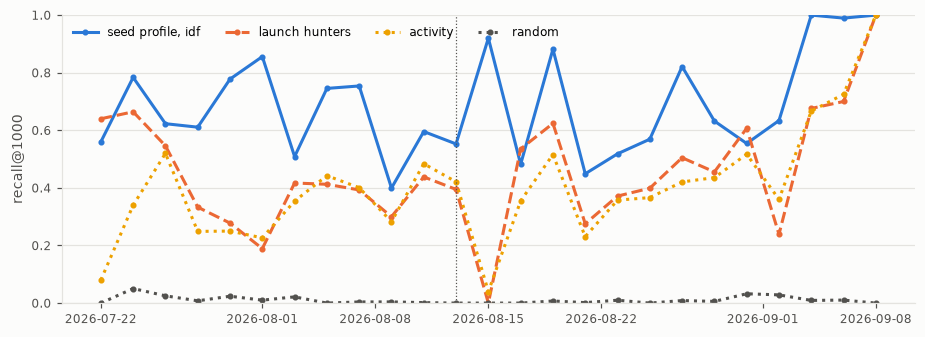

In [7]:
frames = per_point(pd.concat([tokens["dev_b"], tokens["test"]]))
fig, ax = plt.subplots(figsize=(10, 3.4))
for method, colour, style in [(SCORE, plots.SERIES[0], "-"), (BASELINE, plots.SERIES[1], "--"), ("activity" if BASELINE != "activity" else "launch hunters", plots.SERIES[3], ":"), ("random", plots.INK_SECONDARY, ":")]:
    line = frames[frames["method"] == method]
    ax.plot(line["point"], line["recall_1000"], marker="o", markersize=3, color=colour, linestyle=style, label=method)
ax.axvline(pc.POINTS["test"][0], color=plots.INK_SECONDARY, linewidth=0.8, linestyle=":")
ax.set_ylim(0, 1)
ax.set_ylabel("recall@1000")
ax.legend(ncol=4, fontsize=8)
plt.show()

## 5. What this shows

- **The criterion is met, by a wide margin.** One hour after a launch, the seed profile (idf), chosen on Dev A, puts
  **72%** of the token's next-day buyers among its first 1,000 accounts on the test, against 48% for the best
  baseline (launch hunters, also chosen on Dev A): +0.230, interval +0.121 to +0.365, ahead at 11 of 14 points.
  Dev B gives the same picture (+0.237, 10 of 11). The audience holds about 142,000 accounts, so 1,000 is 0.7% of it;
  random accounts find 0.8% of the buyers.
- **A small target list is very precise.** Of the first 100 accounts per token, 12.8% buy within a day, against 3.7%
  for launch hunters (3.5 times as many), at 13 of 14 points.
- **Not farms, not bots buying together with the seeds.** With WP10's farm groups removed, the score finds 63%
  against 36% (+0.275). Counting only buyers who arrive more than 6 hours after launch, it finds 69% against 43%
  (+0.259).
- **What carries it is co-trading.** Accounts whose recent tokens overlap with the first buyers' tokens are the next
  buyers. The recommender's own similarity matrix applied to the seeds also beats the baseline (63% on the test, +0.141,
  interval +0.021 to +0.295), but the direct overlap with the seeds' tokens is stronger, so it was chosen on Dev A.
- **Scope.** Only launches that take off qualify (at least 3 audience accounts in the first hour and 10 buyers after
  it): about 5 per point, 71 on the test. Most new tokens never reach 10 buyers, and most pick-ups of new tokens
  happen inside their first hour, which no list built after it can reach.
- **What it means:** the project's cold start, out of reach for lists made before a token exists, is open one hour
  after launch: the first buyers' histories identify most of the next day's buyers.